<a href="https://colab.research.google.com/github/Prvn31/Transfer-impact/blob/main/Trasnfer_impact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('transfers.csv')

# Expected goal contributions per 90, this season and last
df['xgc_per_90'] = (df['xg'] + df['xa']) / df['minutes'] * 90
df['prev_xgc_per_90'] = (df['prev_xg'] + df['prev_xa']) / df['prev_minutes'] * 90

# Value for money: fee per unit of output (lower = better value)
df['cost_per_xgc90'] = df['fee_m'] / df['xgc_per_90']

# Change since last season, as a percentage
df['xgc_change_pct'] = (df['xgc_per_90'] - df['prev_xgc_per_90']) / df['prev_xgc_per_90'] * 100

# Verdict: above group average = natural fit; small drop = steady; big drop = still adjusting
avg = df['xgc_per_90'].mean()

def fit_verdict(xgc, change):
    if xgc >= avg:
        return '🟢 Natural fit'
    elif change >= -10:
        return '🟡 Steady'
    else:
        return '🔴 Still adjusting'

verdicts = []
for xgc, change in zip(df['xgc_per_90'], df['xgc_change_pct']):
    verdicts.append(fit_verdict(xgc, change))
df['verdict'] = verdicts

# Ranked copy: best output first, numbered from 1 (df itself stays unsorted)
by_output = df.sort_values('xgc_per_90', ascending=False).reset_index(drop=True)
by_output.index = by_output.index + 1

by_output[['name', 'fee_m', 'xgc_per_90', 'cost_per_xgc90', 'xgc_change_pct', 'verdict']].round(2)

,name,fee_m,xgc_per_90,cost_per_xgc90,xgc_change_pct,verdict
1,Gordon,80.0,0.64,125.61,5.22,🟢 Natural fit
2,G.Ramos,73.1,0.60,122.32,-16.67,🟢 Natural fit
3,Savio,87.7,0.41,216.47,-6.44,🟡 Steady
4,Barcola,125.0,0.31,409.60,-61.29,🔴 Still adjusting
5,Diomande,125.0,0.30,422.22,-52.81,🔴 Still adjusting


In [ ]:
teams = pd.read_csv('teams.csv')

# Convert season totals to per match, so a short season compares fairly with a full one
teams['xg_pm'] = teams['xg'] / teams['matches']
teams['prev_xg_pm'] = teams['prev_xg'] / teams['prev_matches']
teams['bc_pm'] = teams['big_chances'] / teams['matches']
teams['prev_bc_pm'] = teams['prev_big_chances'] / teams['prev_matches']

# xG against = xG - xG difference (lower = better defence)
teams['xga_pm'] = (teams['xg'] - teams['xg_diff']) / teams['matches']
teams['prev_xga_pm'] = (teams['prev_xg'] - teams['prev_xg_diff']) / teams['prev_matches']

# Goal difference per match (already per match, so no dividing)
teams['gd_pm'] = teams['goals_pm'] - teams['conceded_pm']
teams['prev_gd_pm'] = teams['prev_goals_pm'] - teams['prev_conceded_pm']

# Change since last season
teams['xg_change'] = teams['xg_pm'] - teams['prev_xg_pm']
teams['xga_change'] = teams['xga_pm'] - teams['prev_xga_pm']  # negative = defence improved
teams['gd_change'] = teams['gd_pm'] - teams['prev_gd_pm']

# Join each signing's stats onto his club's row
combined = teams.merge(df[['name', 'goals', 'assists', 'minutes']], left_on='player', right_on='name')
combined['team_goals'] = (combined['goals_pm'] * combined['matches']).round(0)  # goals are whole numbers
combined['gc_share'] = (combined['goals'] + combined['assists']) / combined['team_goals'] * 100
combined['minutes_share'] = combined['minutes'] / (combined['matches'] * 90) * 100
combined.index = combined.index + 1

combined[['club', 'player', 'xg_change', 'xga_change', 'gd_change', 'gc_share', 'minutes_share']].round(2)

,club,player,xg_change,xga_change,gd_change,gc_share,minutes_share
1,Liverpool,Barcola,-0.10,-0.05,0.1,9.09,48.33
2,Real Madrid,Diomande,0.37,-0.05,0.4,16.00,50.67
3,Spurs,Savio,-0.03,-0.14,-0.1,0.00,45.97
4,Barcelona,Gordon,1.20,-0.09,1.3,12.50,55.11
5,AC Milan,G.Ramos,0.33,0.01,0.6,18.75,86.81


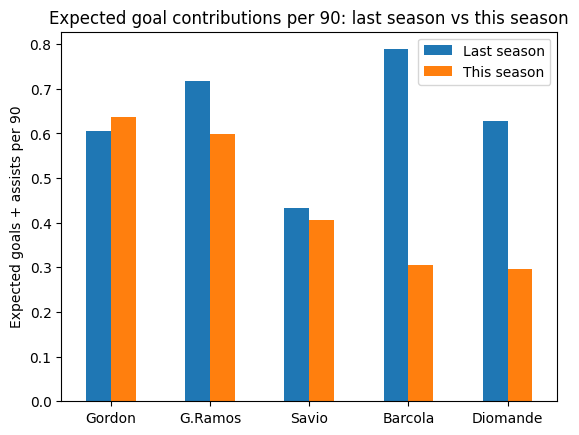

In [ ]:
by_output.plot(x='name', y=['prev_xgc_per_90', 'xgc_per_90'], kind='bar', rot=0)
plt.title('Expected goal contributions per 90: last season vs this season')
plt.xlabel('')
plt.ylabel('Expected goals + assists per 90')
plt.legend(['Last season', 'This season'])
plt.savefig('xgc_this_vs_last.png', dpi=150, bbox_inches='tight')
plt.show()

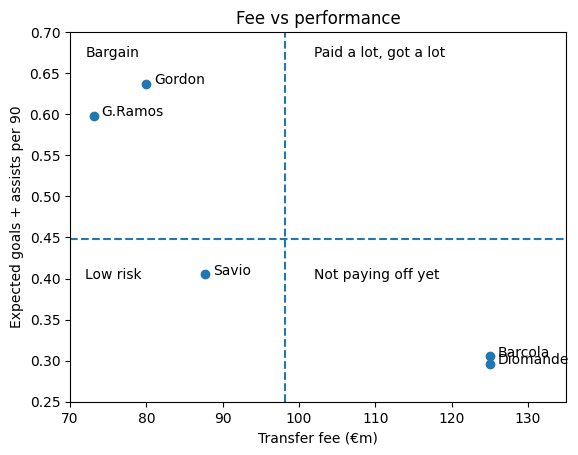

In [ ]:
plt.scatter(df['fee_m'], df['xgc_per_90'])
plt.title('Fee vs performance')
plt.xlabel('Transfer fee (€m)')
plt.ylabel('Expected goals + assists per 90')
for name, fee, xgc in zip(df['name'], df['fee_m'], df['xgc_per_90']):
    plt.text(fee + 1, xgc, name)
plt.axvline(df['fee_m'].mean(), linestyle='--')
plt.axhline(df['xgc_per_90'].mean(), linestyle='--')
plt.xlim(70, 135)
plt.ylim(0.25, 0.70)
plt.text(72, 0.67, 'Bargain')
plt.text(102, 0.67, 'Paid a lot, got a lot')
plt.text(72, 0.40, 'Low risk')
plt.text(102, 0.40, 'Not paying off yet')
plt.savefig('fee_vs_performance.png', dpi=150, bbox_inches='tight')
plt.show()